# Singapore fertility: reproducible exploratory analysis

Question: which observed indicators are associated with Singapore fertility? Common window: 2005–2025. The project quantifies associations and checks time trends. It does not identify causal policy effects.

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
if not (root / "project_config.py").exists():
    root = root.parent
assert (root / "project_config.py").exists(), "Open from the package root or 02_analysis directory"
sys.path.insert(0, str(root))
import pandas as pd
from project_config import DATA, RESULTS, FEATURES, LABELS
from extract_data import main as extract
from run_analysis import main as analyze
from write_findings import main as findings
from analysis_core import association_table, transform
extract()
analyze()
findings()

Extracted 5 annual CSVs. Main dataset: (21, 15).
{
  "start": 2005,
  "end": 2025,
  "n": 21,
  "tfr_2015": 1.24,
  "tfr_latest": 0.87,
  "decade_pct_change": -29.838709677419352,
  "crude_birth_rate_latest": 6.5,
  "resident_live_births_latest": 27393,
  "ridge_alpha": 1.0,
  "model_test_years": [
    2021,
    2025
  ],
  "best_backtest_model": "ridge"
}
       model  n      mae     rmse
 persistence  5 0.054000 0.065879
linear_trend  5 0.089068 0.101341
       ridge  5 0.051615 0.061147
Generated findings report and source guide from the analysis outputs.


## 1. Sources and data quality
Annual CPI requires 12 observations. Household finances use Q4 stocks. No imputation. Actual-rent CPI is supplementary from 2015. All six main indicators have 21 complete years.

In [2]:
d = pd.read_csv(DATA / "analysis_dataset.csv", index_col="year")
display(pd.read_csv(DATA / "data_quality.csv"))
display(pd.read_csv(DATA / "data_dictionary.csv"))
display(d.head())

,dataset,variable,first_year,last_complete_year,available_years,missing_in_analysis
0,births_annual,tfr,1960,2025,66,0
1,births_annual,crude_birth_rate,1960,2025,66,0
2,births_annual,resident_live_births,1980,2025,46,0
3,births_annual,asfr_20_24,1960,2025,66,0
4,births_annual,asfr_25_29,1960,2025,66,0
5,births_annual,asfr_30_34,1960,2025,66,0
6,births_annual,asfr_35_39,1960,2025,66,0
7,births_annual,asfr_40_44,1960,2025,66,0
8,marriages_annual,female_marriage_rate,1980,2025,46,0
9,cpi_annual,cpi_all_items,1961,2025,65,0


,variable,label,unit,role,limitation
0,tfr,Total fertility rate (births per woman),births per woman,outcome / diagnostic,Period fertility measure; national annual aggr...
1,crude_birth_rate,"Crude birth rate (per 1,000 residents)","per 1,000 residents",outcome / diagnostic,Period fertility measure; national annual aggr...
2,resident_live_births,Resident live births (number),number,outcome / diagnostic,Period fertility measure; national annual aggr...
3,asfr_20_24,Age-specific fertility rate 20–24,"births per 1,000 women in age group",outcome / diagnostic,Period fertility measure; national annual aggr...
4,asfr_25_29,Age-specific fertility rate 25–29,"births per 1,000 women in age group",outcome / diagnostic,Period fertility measure; national annual aggr...
5,asfr_30_34,Age-specific fertility rate 30–34,"births per 1,000 women in age group",outcome / diagnostic,Period fertility measure; national annual aggr...
6,asfr_35_39,Age-specific fertility rate 35–39,"births per 1,000 women in age group",outcome / diagnostic,Period fertility measure; national annual aggr...
7,asfr_40_44,Age-specific fertility rate 40–44,"births per 1,000 women in age group",outcome / diagnostic,Period fertility measure; national annual aggr...
8,female_marriage_rate,Female general marriage rate,"per 1,000 unmarried resident women aged 15–49",candidate predictor,Marriage formation proxy. Does not measure mar...
9,cpi_all_items,General consumer prices,"index, 2024=100",candidate predictor,Consumer price level. Does not measure househo...


,tfr,crude_birth_rate,resident_live_births,asfr_20_24,asfr_25_29,asfr_30_34,asfr_35_39,asfr_40_44,female_marriage_rate,cpi_all_items,cpi_actual_rent,cpi_accommodation,cpi_education,rail_length_km,household_debt_asset_pct
year,,,,,,,,,,,,,,,
2005,1.26,10.2,35528.0,32.5,80.7,89.2,36.8,6.2,39.0,66.043083,NaN,65.357583,59.372417,138.2,19.217727
2006,1.28,10.3,36272.0,30.6,79.6,93.1,38.7,6.4,40.0,66.680833,NaN,65.829333,61.237417,138.2,17.697110
2007,1.29,10.3,37074.0,31.2,78.7,94.4,41.5,6.4,40.1,68.087667,NaN,66.886667,62.918250,138.2,16.302263
2008,1.28,10.2,37277.0,29.1,78.9,94.6,41.5,6.6,39.6,72.605583,NaN,76.363000,65.871417,138.2,16.907666
2009,1.22,9.9,36925.0,25.4,74.2,90.1,42.6,7.0,38.9,73.033333,NaN,80.468417,66.410167,147.7,16.045645


## 2. Descriptive analysis
Use TFR as the primary outcome. Crude birth rate and resident live-birth counts have distinct units and denominators.

,count,mean,std,min,25%,50%,75%,max
tfr,21.0,1.160000,0.116533,0.870000,1.120000,1.190000,1.250000,1.290000
crude_birth_rate,21.0,9.085714,1.070647,6.500000,8.600000,9.300000,9.900000,10.300000
resident_live_births,21.0,35078.428571,2784.093920,27393.000000,34233.000000,35528.000000,36925.000000,38641.000000
asfr_20_24,21.0,18.976190,7.566036,8.700000,12.700000,18.700000,23.300000,32.500000
asfr_25_29,21.0,64.276190,13.144995,38.100000,54.600000,68.100000,74.200000,80.700000
asfr_30_34,21.0,90.347619,7.249939,69.700000,89.200000,92.400000,94.400000,99.500000
asfr_35_39,21.0,46.076190,4.361755,36.800000,42.400000,47.900000,49.400000,53.600000
asfr_40_44,21.0,8.304762,1.421083,6.100000,7.000000,8.800000,9.500000,10.200000
female_marriage_rate,21.0,39.966667,2.640896,34.900000,38.900000,40.000000,41.100000,45.500000
cpi_all_items,21.0,83.085730,10.136164,66.043083,75.099333,85.046250,85.942167,100.903167


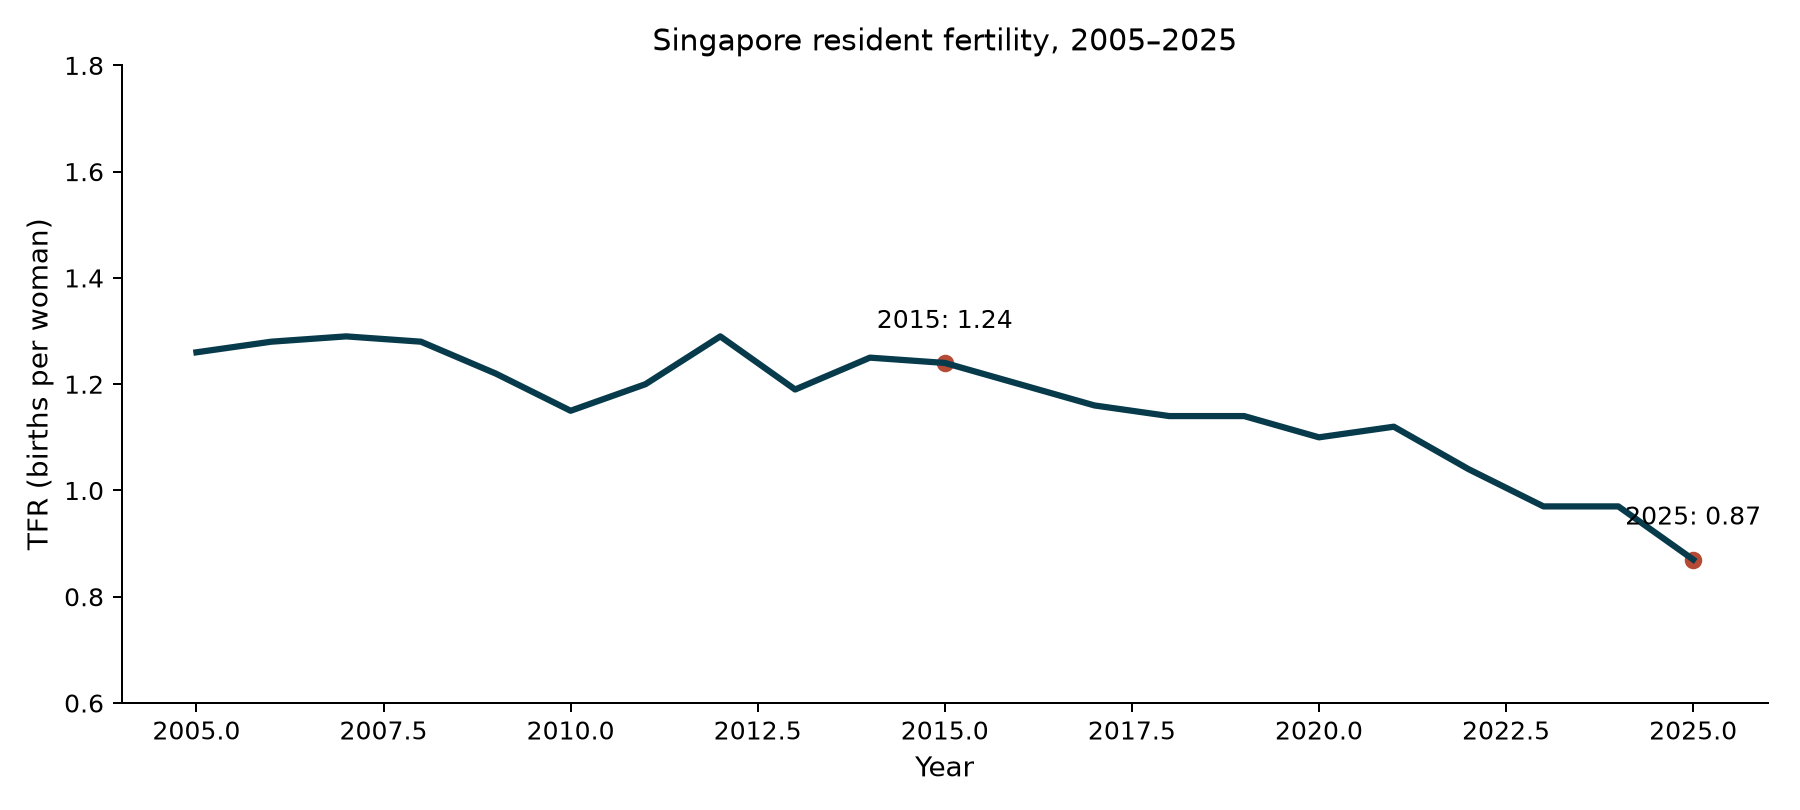

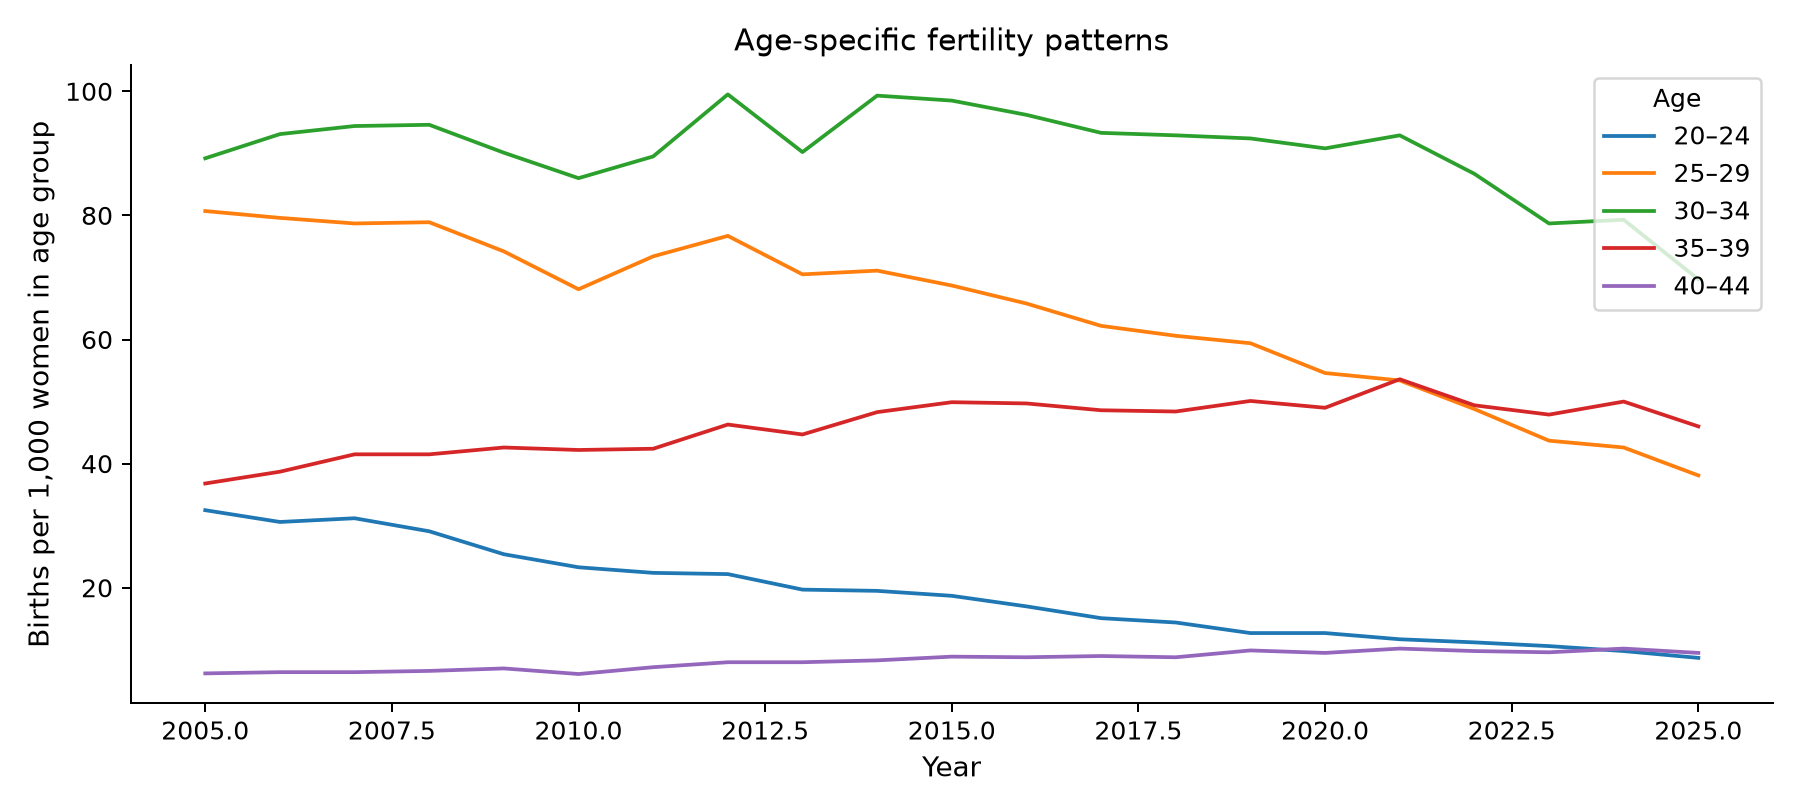

In [3]:
display(d.describe().T)
from IPython.display import Image, display
display(Image(filename=str(RESULTS / "fertility_trend.png")))
display(Image(filename=str(RESULTS / "age_specific_fertility.png")))

## 3. Six candidate factors
Compare levels, absolute annual changes, and residuals after subtracting a linear time trend. Strong level correlations can arise from shared trends. Slope intervals use HAC lag 1. BH q-values adjust the six slope comparisons within each mode.

,variable,mode,n,first_year,last_year,correlation,pearson_p,slope,ci_low,ci_high,hac_p,slope_per_sd,bh_q
0,female_marriage_rate,Levels,21,2005,2025,-0.111453,6.305364e-01,-0.004918,-0.021904,0.012068,5.703812e-01,-0.012988,5.703812e-01
1,cpi_all_items,Levels,21,2005,2025,-0.844715,1.459568e-06,-0.009712,-0.012738,-0.006685,3.207444e-10,-0.098437,6.414887e-10
2,cpi_accommodation,Levels,21,2005,2025,-0.518355,1.606996e-02,-0.005222,-0.009729,-0.000715,2.314322e-02,-0.060406,2.777186e-02
3,cpi_education,Levels,21,2005,2025,-0.837724,2.154781e-06,-0.007276,-0.009816,-0.004735,1.987270e-08,-0.097623,2.980905e-08
4,household_debt_asset_pct,Levels,21,2005,2025,0.914655,6.572082e-09,0.044389,0.034477,0.054300,1.669597e-18,0.106588,1.001758e-17
5,rail_length_km,Levels,21,2005,2025,-0.869953,3.001025e-07,-0.002163,-0.002818,-0.001509,9.221843e-11,-0.101378,2.766553e-10
6,female_marriage_rate,Annual changes,20,2006,2025,0.497450,2.563366e-02,0.008476,0.002108,0.014843,9.082192e-03,0.026197,5.449315e-02
7,cpi_all_items,Annual changes,20,2006,2025,0.042817,8.577520e-01,0.001267,-0.013952,0.016485,8.704318e-01,0.002255,8.704318e-01
8,cpi_accommodation,Annual changes,20,2006,2025,0.198774,4.008318e-01,0.002796,-0.003369,0.008962,3.740495e-01,0.010468,6.208135e-01
9,cpi_education,Annual changes,20,2006,2025,0.267403,2.543827e-01,0.014956,-0.002529,0.032440,9.363603e-02,0.014082,2.809081e-01


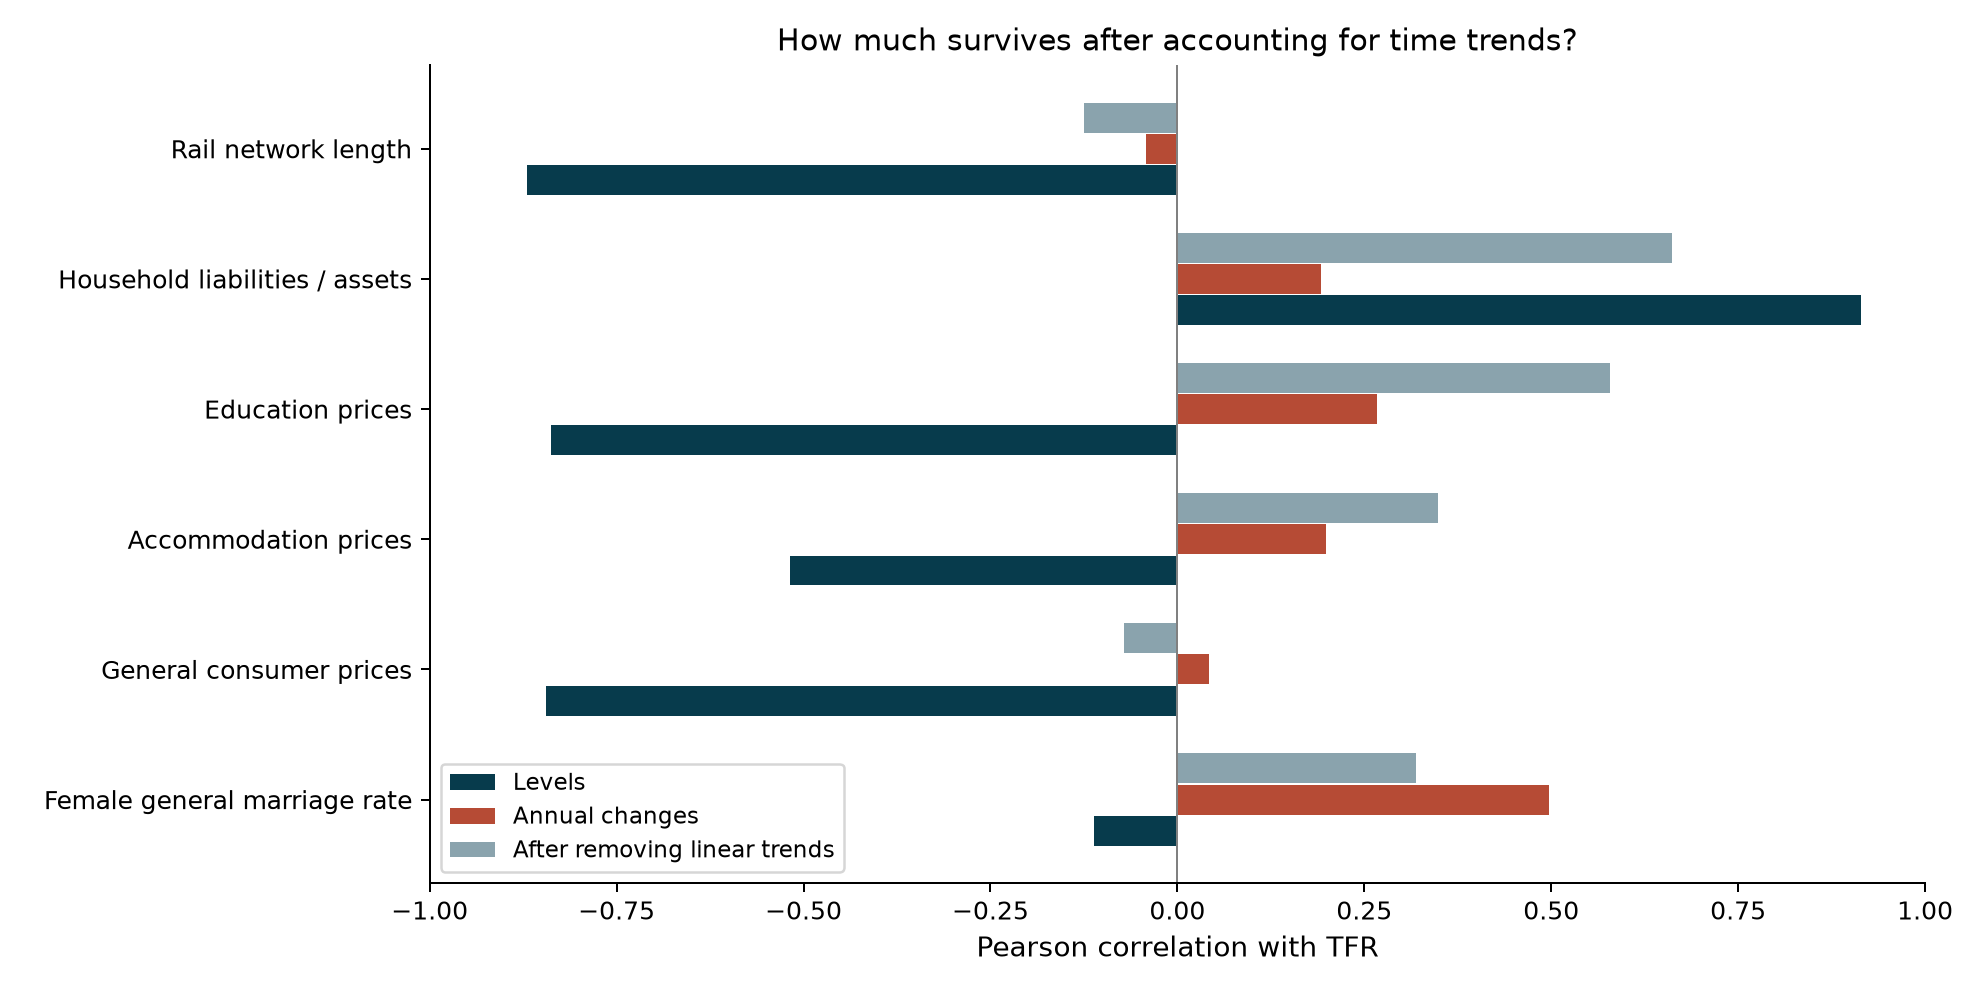

,variable,mode,n,first_year,last_year,correlation,pearson_p,slope,ci_low,ci_high,hac_p,slope_per_sd,bh_q
0,female_marriage_rate,Annual changes,20,2006,2025,0.497450,0.025634,0.008476,0.002108,0.014843,0.009082,0.026197,0.054493
1,cpi_all_items,Annual changes,20,2006,2025,0.042817,0.857752,0.001267,-0.013952,0.016485,0.870432,0.002255,0.870432
2,cpi_accommodation,Annual changes,20,2006,2025,0.198774,0.400832,0.002796,-0.003369,0.008962,0.374050,0.010468,0.620814
3,cpi_education,Annual changes,20,2006,2025,0.267403,0.254383,0.014956,-0.002529,0.032440,0.093636,0.014082,0.280908
4,household_debt_asset_pct,Annual changes,20,2006,2025,0.191771,0.417960,0.014932,-0.020885,0.050748,0.413876,0.010099,0.620814
5,rail_length_km,Annual changes,20,2006,2025,-0.041902,0.860764,-0.000273,-0.001973,0.001427,0.752724,-0.002207,0.870432


In [4]:
associations = pd.read_csv(RESULTS / "associations.csv")
display(associations)
display(Image(filename=str(RESULTS / "associations.png")))
display(pd.read_csv(RESULTS / "six_variable_effects.csv"))

## 4. Sensitivity analysis
Exclude pandemic years before calculating differences. Reindexing preserves the gap, so a two- or three-year change cannot masquerade as an annual change. Also test crude birth rate and one-year-lagged levels. These screens are exploratory.

In [5]:
display(pd.read_csv(RESULTS / "pandemic_sensitivity.csv"))
display(pd.read_csv(RESULTS / "crude_birth_rate_sensitivity.csv"))
display(pd.read_csv(RESULTS / "lagged_associations.csv"))

,variable,mode,n,first_year,last_year,correlation,pearson_p,slope,ci_low,ci_high,hac_p,slope_per_sd,bh_q
0,female_marriage_rate,Annual changes,17,2006,2025,0.623339,0.007508,0.015090,0.008574,0.021605,0.000006,0.033767,0.000034
1,cpi_all_items,Annual changes,17,2006,2025,0.177735,0.494943,0.005865,-0.010480,0.022210,0.481858,0.009628,0.637558
2,cpi_accommodation,Annual changes,17,2006,2025,0.245188,0.342864,0.003295,-0.002625,0.009216,0.275334,0.013282,0.550669
3,cpi_education,Annual changes,17,2006,2025,0.348084,0.170954,0.025883,0.003118,0.048649,0.025854,0.018856,0.077561
4,household_debt_asset_pct,Annual changes,17,2006,2025,0.153953,0.555224,0.011910,-0.025377,0.049196,0.531299,0.008340,0.637558
5,rail_length_km,Annual changes,17,2006,2025,-0.029762,0.909721,-0.000191,-0.001974,0.001593,0.833999,-0.001612,0.833999


,variable,mode,n,first_year,last_year,correlation,pearson_p,slope,ci_low,ci_high,hac_p,slope_per_sd,bh_q
0,female_marriage_rate,Annual changes,20,2006,2025,0.445525,0.048990,0.058088,0.009579,0.106597,0.018925,0.179539,0.113550
1,cpi_all_items,Annual changes,20,2006,2025,-0.011891,0.960316,-0.002692,-0.110413,0.105030,0.960941,-0.004792,0.960941
2,cpi_accommodation,Annual changes,20,2006,2025,0.184885,0.435181,0.019903,-0.022076,0.061882,0.352764,0.074505,0.538940
3,cpi_education,Annual changes,20,2006,2025,0.237244,0.313865,0.101536,-0.040687,0.243759,0.161735,0.095605,0.485205
4,household_debt_asset_pct,Annual changes,20,2006,2025,0.128173,0.590214,0.076366,-0.167054,0.319785,0.538635,0.051651,0.646361
5,rail_length_km,Annual changes,20,2006,2025,-0.131282,0.581152,-0.006552,-0.020560,0.007456,0.359293,-0.052904,0.538940


,variable,mode,n,first_year,last_year,correlation,pearson_p,slope,ci_low,ci_high,hac_p,slope_per_sd,bh_q
0,female_marriage_rate,Levels,20,2006,2025,-0.420639,6.477833e-02,-0.018442,-0.034693,-0.002192,2.612884e-02,-0.049310,3.135460e-02
1,cpi_all_items,Levels,20,2006,2025,-0.828473,6.431671e-06,-0.010203,-0.013554,-0.006852,2.417374e-09,-0.097119,6.828905e-09
2,cpi_accommodation,Levels,20,2006,2025,-0.485339,3.006678e-02,-0.004953,-0.009600,-0.000305,3.675693e-02,-0.056895,3.675693e-02
3,cpi_education,Levels,20,2006,2025,-0.847908,2.348926e-06,-0.007678,-0.010364,-0.004992,2.117005e-08,-0.099397,3.175508e-08
4,household_debt_asset_pct,Levels,20,2006,2025,0.912901,1.990387e-08,0.047709,0.039189,0.056229,5.001162e-28,0.107016,3.000697e-27
5,rail_length_km,Levels,20,2006,2025,-0.870934,5.853714e-07,-0.002266,-0.003018,-0.001515,3.414452e-09,-0.102097,6.828905e-09


## 5. Predictive backtest
Ridge uses the previous year’s six indicators plus calendar year. Tune only on expanding validation years 2016–2020. Refit before each test year 2021–2025. Compare persistence and linear trend. Source revisions and publication delays prevent real-time performance claims.

,alpha,validation_mae
0,0.1,0.059882
1,1.0,0.039322
2,10.0,0.044794
3,100.0,0.065734
4,1000.0,0.078249


,model,n,mae,rmse
0,persistence,5,0.054000,0.065879
1,linear_trend,5,0.089068,0.101341
2,ridge,5,0.051615,0.061147


,year,actual,persistence,linear_trend,ridge
0,2021,1.12,1.10,1.129500,1.081214
1,2022,1.04,1.12,1.117574,1.069604
2,2023,0.97,1.04,1.090458,1.029701
3,2024,0.97,0.97,1.053860,0.988617
4,2025,0.87,0.97,1.023947,0.981368


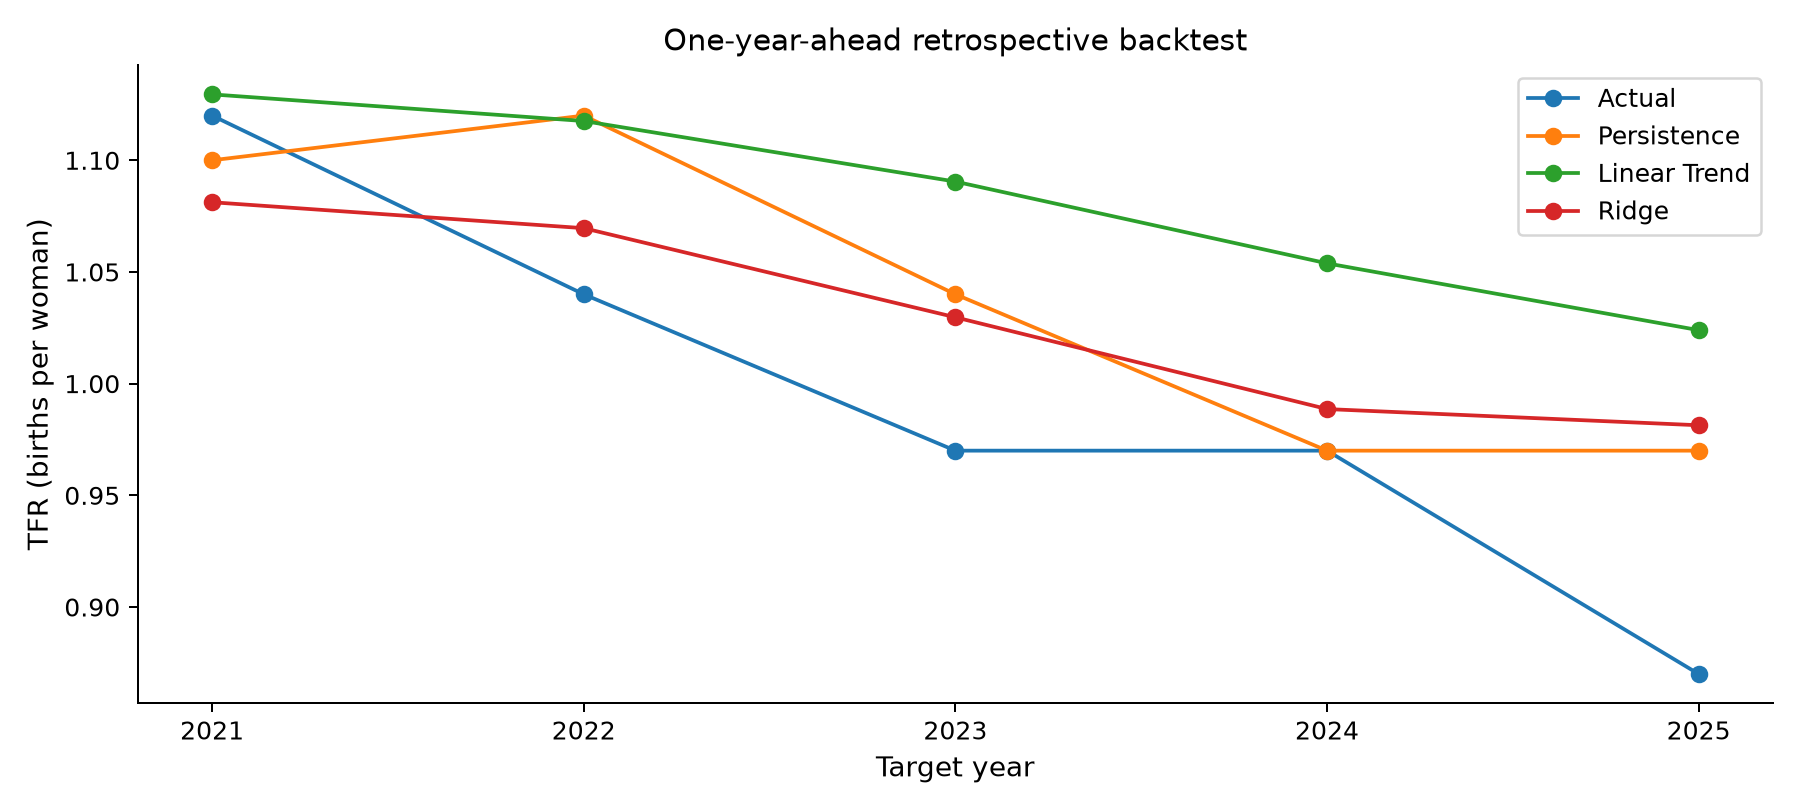

In [6]:
display(pd.read_csv(RESULTS / "ridge_tuning.csv"))
display(pd.read_csv(RESULTS / "backtest_scores.csv"))
display(pd.read_csv(RESULTS / "backtest_predictions.csv"))
display(Image(filename=str(RESULTS / "backtest.png")))

## 6. Interpretation and policy
Read `04_findings/findings_report.md` for the generated conclusions. The strongest annual-change marriage association has adjusted q approximately 0.0545 in the full sample. No six-factor causal ranking is justified. Policy proposals require direct housing, childcare, work and intentions data plus pilot evaluation.

Launch the interactive dashboard with `python -m streamlit run 03_dashboard/app.py` from the package root.